<a href="https://colab.research.google.com/github/Pronathan/na3a-programmering/blob/main/brawlistic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random

# debug = True

# def slowtype(text, delay, debug):
#    if debug:
#        return

mega_stats = []

for i in range(0, 10):

    stats = []
    rounds = 100

    for i in range(0, rounds):

        spelare_hp = 20
        spelare_aggro = 0.8 # justera för att se att det verkligen fungerar
        fiende_aggro = 0.67
        fiende_hp = 20
        moves = ["attack", "försvar"]

        while spelare_hp > 0 and fiende_hp > 0:
            spelare_slag = 0 # vi måste nollställa annars blir försvar slag + heal
            fiende_slag = 0
            spelare_move = random.random() # pinsamt, vi kan inte använda randint och jmf med 0.67
            fiende_move = random.random()

            if spelare_aggro > spelare_move:
                spelare_slag = random.randint(3, 8) # balansera
            else:
                spelare_hp += 2

            if fiende_aggro > fiende_move:
                fiende_slag = random.randint(2, 6) # balansera
            else:
                fiende_hp += 1

            fiende_hp -= spelare_slag
            spelare_hp -= fiende_slag

        # print(spelare_hp, fiende_hp)
        stats.append([spelare_hp, fiende_hp])

    mega_stats.append(stats)

# print(stats)


In [ ]:
def calc_from_stats(stats):
    global medel, spelare_win, fiende_win, draw
    for stat in stats:
        spelare_hp = stat[0]
        fiende_hp = stat[1]
        # fixa till villkoren så att vi inte kan få situationer då båda har negativ hp
        if spelare_hp > 0  and fiende_hp <= 0:
            spelare_win += 1
        elif spelare_hp <= 0 and fiende_hp > 0:
            fiende_win += 1
        else:
            draw += 1

        medel.append(spelare_hp - fiende_hp)

medel = []
spelare_win = 0
fiende_win = 0
draw = 0

calc_from_stats(stats)

print(f"spelare vinster: {spelare_win} fiende vinster: {fiende_win} lika: {draw}")
print(f"Det är % chans att spelare vinner: {spelare_win / rounds * 100}")
print(sum(medel) / len(medel))

spelare vinster: 92 fiende vinster: 5 lika: 3
Det är % chans att spelare vinner: 92.0
9.68


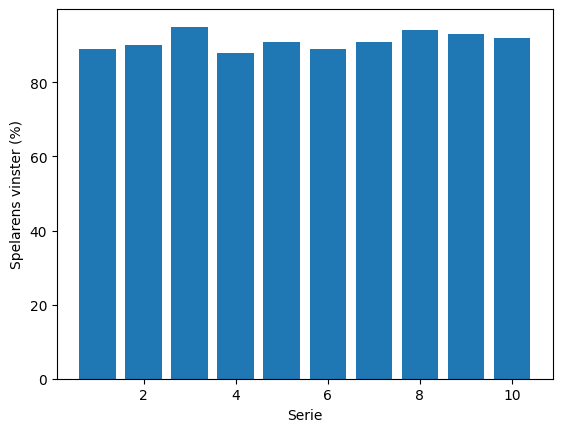

In [ ]:
import matplotlib.pyplot as plt

vinstandelar = []
for serie in mega_stats:
    vinster = 0
    for spelare_hp, fiende_hp in serie:
        if spelare_hp > 0 and fiende_hp <= 0:
            vinster += 1
    vinstandelar.append(vinster / len(serie) * 100)

plt.bar(range(1, len(vinstandelar) + 1), vinstandelar)
plt.xlabel("Serie")
plt.ylabel("Spelarens vinster (%)")
plt.show()

In [ ]:
enemies = [
    {
        "type": "goblin",
        "hp": 10,
        "attacks": [
            {
                "name": "sneaky stab",
                "damage": (3, 6) # tuple vi kan mata in random.randint(damage[0], damage[1])
            }
        ]
    },
    {
        "type": "orc",
        "hp": 20,
        "attacks": [
            {
                "name": "orc smash",
                "damage": (4, 12)
            },
            {
                "name": "bad breath",
                "damage": (2, 4)
            }
        ]
    }
]

enemy = random.choice(enemies) # eftersom enemies innehåller flera lika objekt
# kan koden som följer som "använder" dem se likadan ut

print(enemy["type"])
print(enemy["attacks"][0])

# men för att använda dem så behöver vi kopiera dem
# om vi gör, så ändrar vi alla goblins hp

# enemies[0]["hp"] -= 5

# print(enemies[0]["hp"])

# utan det vi ska göra är tilldela fienden när vi väljer den

current_enemy = random.choice(enemies)

current_enemy["hp"] -= 5

print(current_enemy)

# nästa steg är väl fler attacker
# de kan kosta energi, enemy["energy"]
# så dår får man kolla med if om attacken går att göra
# sen kan vi också ha "gear": [{"type": "armor", "defense": 10}]
# som då kan påverka skada åt båda hållen


goblin
{'name': 'sneaky stab', 'damage': (3, 6)}
{'type': 'goblin', 'hp': 5, 'attacks': [{'name': 'sneaky stab', 'damage': (3, 6)}]}
